In [ ]:
# Hosted D2L setup: fetch the exact helper module used to build this notebook.
from pathlib import Path
from urllib.request import urlretrieve
from importlib.metadata import PackageNotFoundError, version
import importlib.util, os, subprocess, sys

required = ['numpy', 'pandas', 'matplotlib', 'requests', 'scipy', 'pillow', 'regex', 'torch', 'torchvision']
imports = {'pillow': 'PIL'}
pinned = {}
fallbacks = {'torch': 'torch==2.11.0', 'torchvision': 'torchvision==0.26.0'}
device = os.environ.get("D2L_HOSTED_DEVICE", "auto").lower()
if device not in ("auto", "cpu", "gpu"):
    raise ValueError(f"Invalid D2L_HOSTED_DEVICE={device!r}")
if device == "auto":
    try:
        gpu = (Path("/dev/nvidia0").exists() or
               subprocess.run(["nvidia-smi", "-L"], capture_output=True,
                              timeout=5).returncode == 0)
    except (FileNotFoundError, subprocess.SubprocessError):
        gpu = False
else:
    gpu = device == "gpu"
if not gpu:
    os.environ.setdefault("CUDA_VISIBLE_DEVICES", "-1")
    os.environ.setdefault("JAX_PLATFORMS", "cpu")
tensorflow_version = None
if 'pytorch' in ("tensorflow", "jax"):
    try:
        tensorflow_version = version("tensorflow")
    except PackageNotFoundError:
        pass
# Colab's CPU image currently carries a CUDA-enabled TensorFlow wheel. Its
# first ordinary tensor operation probes CUDA and emits an error-level cuInit
# diagnostic. JAX notebooks also use TensorFlow for data loading, so overlay
# the matching CPU build in both CPU variants. Keep the provider's
# ``tensorflow`` distribution metadata: other preinstalled Colab packages
# depend on that distribution name, while both wheels expose the same module.
if not gpu and 'pytorch' in ("tensorflow", "jax"):
    try:
        tensorflow_cpu_version = version("tensorflow-cpu")
    except PackageNotFoundError:
        tensorflow_cpu_version = None
    if (tensorflow_version is not None and
            tensorflow_cpu_version != tensorflow_version):
        subprocess.check_call([
            sys.executable, "-m", "pip", "install", "-q", "--no-deps",
            f"tensorflow-cpu=={tensorflow_version}",
        ])
if "tf-keras" in fallbacks and tensorflow_version is not None:
    fallbacks["tf-keras"] = f"tf-keras=={tensorflow_version}"
missing = []
for package in required:
    if package in pinned:
        wanted, cpu_requirement, gpu_requirement, match = pinned[package]
        requirement = gpu_requirement if gpu else cpu_requirement
        if requirement is None:  # a GPU-only package on a CPU runtime
            continue
        try:
            installed = version(package)
        except PackageNotFoundError:
            installed = None
        actual = (installed.split("+", 1)[0]
                  if installed is not None and match == "public" else installed)
        if actual != wanted:
            missing.append(requirement)
    elif importlib.util.find_spec(imports.get(package, package)) is None:
        missing.append(fallbacks.get(package, package))
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

mismatched = []
for package, (wanted, cpu_requirement, _, match) in pinned.items():
    if not gpu and cpu_requirement is None:
        continue
    try:
        installed = version(package)
    except PackageNotFoundError:
        installed = None
    actual = (installed.split("+", 1)[0]
              if installed is not None and match == "public" else installed)
    if actual != wanted:
        mismatched.append(f"{package}={installed!r} (expected {wanted})")
if mismatched:
    raise RuntimeError("Hosted runtime setup failed: " + ", ".join(mismatched))

root = Path(".d2l-hosted") / "85bd815efd86af24338a0f0c45844cb7e1e6f155"
package = root / "d2l"
package.mkdir(parents=True, exist_ok=True)
base = "https://raw.githubusercontent.com/smolix/d2l-neu/85bd815efd86af24338a0f0c45844cb7e1e6f155/d2l"
for name in ('__init__.py', 'torch.py'):
    target = package / name
    if not target.exists():
        urlretrieve(f"{base}/{name}", target)
if str(root.resolve()) not in sys.path:
    sys.path.insert(0, str(root.resolve()))
pythonpath = os.environ.get("PYTHONPATH", "").split(os.pathsep)
if str(root.resolve()) not in pythonpath:
    os.environ["PYTHONPATH"] = os.pathsep.join(
        [str(root.resolve()), *[entry for entry in pythonpath if entry]]
    )


# Stochastic Differential Equations

Every trajectory in the previous sections was fixed by its start, and a flow
never forgets where it came from: two starts always reach two different
ends. The diffusion models of that section are built on
a process that does forget. Their *forward process* mixes new noise into its
state, a little at a time, until nothing of the start remains, and
generation, which runs it backward, has a known place to begin. Such a
process solves a differential equation too, but not one that ordinary
calculus can handle.

Let us begin with a case small enough to follow by hand. Take one number,
$x_0 = 2$. At each step keep $99\%$ of it and add an independent Gaussian
draw of standard deviation $\sqrt{0.02} \approx 0.14$:

$$
x_{k+1} = 0.99\, x_k + \sqrt{0.02}\; \xi_k, \qquad \xi_k \sim \mathcal{N}(0, 1).
$$

After $400$ steps the mean is $2 \cdot 0.99^{400} \approx 0.036$, and the
variance is close to $1$, where the $2\%$ that a step removes balances the
$0.02$ that it adds. Any other start ends in the same place, a draw from
nearly $\mathcal{N}(0, 1)$. One feature of the recurrence looks odd. If it
describes a process in continuous time with time step $h = 0.01$, then the
decay $0.99 = 1 - h$ changes $x$ by an amount of order $h$, but the noise
has size $\sqrt{h}$, not $h$. This choice is forced.
Noise of size $h$ would vanish as $h \to 0$, while noise of size $\sqrt{h}$
survives, and its square is of order $h$, the same order as the drift.
Ordinary calculus discards squares of small changes, so this one fact
requires a new calculus.

The limit of such noise is Brownian motion, named after the botanist Robert
Brown, who in 1827 watched particles from pollen grains jitter in water.
Norbert Wiener made it a mathematical object in 1923, and Kiyoshi Itô built
its calculus in the
1940s [@Ito.1944] on one rule: the squares of short Brownian increments
add up to the elapsed time, so the chain rule gains a second-derivative
term.

We build Brownian motion from coin flips and the calculus from that rule.
Then we solve the process behind the recurrence, the forward process of
that section. Given the start, its distribution at
every time is a Gaussian, so a diffusion model can noise its data to any
level in one draw. Simulation, and the measurement of its error, can wait
for a second reading. Only the rule for squares is hard to believe, and its
proof takes six lines.

In [1]:
import math
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from d2l import torch as d2l

## Brownian Motion

### Noise as a Forward Process

Before building any machinery, let us check what a forward process must do.
Starting from data distributed as $p_0 = p_{\textrm{data}}$, it must end at
one known distribution, whatever the data looked like,

$$
p_0 = p_{\textrm{data}} \;\longrightarrow\; p_T \approx \mathcal{N}(\mathbf{0}, \mathbf{I}),
$$

so that generation always knows where to start. No fixed flow does this for
two datasets at once. A flow is an invertible map $\Phi$
(that section), so if it carried two distributions $p$ and
$q$ to the same one, applying $\Phi^{-1}$ would show $p = q$.

Let us try three processes on two "datasets" that are as simple as datasets
can be: point masses at $x_0 = 2$ and at $x_0 = -2$.

- **Drift alone**, $\dot{x} = -x$. The solution $x(t) = x_0 e^{-t}$ puts the
  two starts at $\pm 2e^{-3} = \pm 0.0996$ at $t = 3$. They approach the
  point $0$, which is not a Gaussian, and at every finite time they are still
  two distinct points.
- **Noise alone**, $dX = \sqrt{2}\, dW$, which means
  $X_t = x_0 + \sqrt{2}\, W_t$ for a noise $W$ whose variance grows linearly
  in time (the next subsection constructs it). The distribution of $X_t$,
  its *law*, is $\mathcal{N}(x_0, 2t)$: each cloud keeps its center at
  $\pm 2$ while its standard deviation $\sqrt{2t}$ grows without bound ($2.45$ at $t = 3$). The
  start is forgotten only relative to this growing width, and there is no
  limiting law.
- **Both together**, $dX = -X\,dt + \sqrt{2}\, dW$. From either start the law
  at $t = 3$ is $\mathcal{N}(\pm 0.0996,\, 0.9975)$, as
  that section proves. The two laws are nearly
  indistinguishable from each other and from $\mathcal{N}(0, 1)$.

![One failure, one usable process and the one we use, from the two starts $x_0=\pm2$. Drift alone sends every start to the point $0$. Noise alone keeps each start as the center of a cloud whose two-standard-deviation envelope $x_0\pm2\sqrt{2t}$ (dashed) grows without bound. Both together carry every start into the same limiting law $\mathcal N(0,1)$, drawn sideways at the right. Green lines are the means.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/mdl-dyn-sde-paths.svg)

the figure draws the three. Only the first fails
outright. The second is usable, and is in use. Once its variance $2t$ is far
larger than that of the data, the start hardly matters. Processes of this
kind are called *variance-exploding*, because without a limiting law they
must make their final variance huge. The third is the running example of
this section, and the recurrence of the opening simulates it. Its drift pulls each start toward zero while the noise refills
the variance that the drift removes, and the two balance at variance $1$.

In general, a forward process of this kind is a deterministic vector field
plus a noise term. For data in $\mathbb{R}^d$ we write

$$
d\mathbf{X} \;=\; \underbrace{\mathbf{f}(\mathbf{X}, t)\,dt}_{\textrm{drift}}
\;+\; \underbrace{g(t)\,d\mathbf{W}}_{\textrm{diffusion}},
$$

which reads: over a short time $dt$, the state moves by the velocity
$\mathbf{f}$ times $dt$ and receives a random kick whose size is set by the
noise amplitude $g$. The drift steers the mean, and the diffusion injects
variance. So far the kick $d\mathbf{W}$ is only a symbol. We give it a
meaning in one coordinate, and return to $\mathbb{R}^d$ only at the end of
the Itô calculus.

### From Random Walks to the Wiener Process

We put an object behind the symbol by taking the limit of the simplest random
process there is, a walk driven by coin flips. The limit explains the square
root in our recurrence.

Fix a step duration $\Delta t$ and let a walker take independent steps of size
$\pm\sqrt{\Delta t}$, each sign chosen by a fair coin. After $k$ steps, at time
$t = k\,\Delta t$, the position is a sum of $k$ independent mean-zero steps of
variance $\Delta t$ apiece. Variances of independent terms add
(that section), so

$$
\mathbb{E}\!\left[W^{(\Delta t)}_t\right] = 0,
\qquad
\textrm{Var}\!\left(W^{(\Delta t)}_t\right) = k\,\Delta t = t,
$$

whatever the step size. With $\Delta t = 0.01$, for instance, $100$ steps of
$\pm 0.1$ give variance $100 \cdot 0.01 = 1$ at time $1$. Steps of $\pm 0.01$
on the same clock would give variance $0.01$, and steps of $\pm 1$ would give
$100$. In general, steps of size $c\,\Delta t^{a}$ give variance
$c^2\, t\, \Delta t^{2a - 1}$ at time $t$,
which tends to $0$ for $a > \tfrac12$ and to $\infty$ for $a < \tfrac12$.
Only the square root leaves a finite nonzero variance in the limit, which is
why it returns in the noise term of every numerical scheme below.

As $\Delta t \to 0$ the number of steps before time $t$ grows without bound,
and the central limit theorem (that section) makes the
position Gaussian: a sum of many independent mean-zero terms with total
variance $t$ is approximately $\mathcal{N}(0, t)$.

The limit process is called **Brownian motion** or the **Wiener process**
[@Wiener.1923]. It is defined by four properties:

1. $W_0 = 0$;
2. **independent increments**: for $s < t$, the increment $W_t - W_s$ is
   independent of the entire path up to time $s$;
3. **Gaussian increments**: $W_t - W_s \sim \mathcal{N}(0,\, t - s)$;
4. continuous sample paths.

That a process with these properties exists is Wiener's theorem, and that the
rescaled walks converge to it is Donsker's theorem; we take both as given.
The process spreads with standard deviation $\sqrt{t}$ forever
(the figure), and its increments have the form

$$
\Delta W \;=\; W_{t + \Delta t} - W_t \;=\; \sqrt{\Delta t}\;\xi,
\qquad \xi \sim \mathcal{N}(0, 1),
$$

a standard normal draw scaled by $\sqrt{\Delta t}$.

![One coin-flip walk of $1000$ steps $\pm\sqrt{0.001}$, viewed on meshes $\Delta t=0.1$, $0.01$ and $0.001$ (faint gray: the full path). Each view is itself a random walk with step variance $\Delta t$; refining the mesh fills in detail without changing the large-scale path. At each fixed time the spread follows the $\pm\sqrt t$ and $\pm2\sqrt t$ envelopes.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/mdl-dyn-brownian-paths.svg)

Independent increments also fix how the values of $W$ at two times are
related. For $s \le t$ write $W_t = W_s + (W_t - W_s)$. The increment is
independent of $W_s$ and has mean zero, so
$\textrm{Cov}(W_s, W_t) = \mathbb{E}[W_s^2] = s = \min(s, t)$: the walk
carries its position at time $s$ forward and adds noise that is uncorrelated
with it. The formula is worth more than its one-line proof suggests.
Jointly Gaussian values are determined by their means and covariances, so a
process with jointly Gaussian values at any finite set of times, mean zero,
covariance $\min(s, t)$ and continuous paths is a Brownian motion.

The same increments make the path rough. Brownian paths are continuous but
nowhere differentiable, a theorem of Paley, Wiener, and Zygmund
[@Paley.Wiener.Zygmund.1933]. The increment scaling
the equation gives the heuristic reason:

$$
\left|\frac{\Delta W}{\Delta t}\right|
= \frac{|\xi|}{\sqrt{\Delta t}}
\;\longrightarrow\; \infty
\quad \textrm{in probability as } \Delta t \to 0,
$$

so a difference quotient grows without bound as the step shrinks. This is not
a proof (it rules out a derivative at each fixed time, while "nowhere"
concerns all times at once), but it shows the obstruction.

Rescaling time by a factor $c$ and space by $\sqrt{c}$ returns a Brownian
motion (Exercise 2), so zooming
in on a path shows the same roughness at every scale, where a differentiable
curve would flatten into its tangent. Hence $dW/dt$ does not exist, and $dW$
has to be given a meaning inside integrals. The Itô calculus supplies that
meaning.

### Simulation of Brownian Paths

The increment form the equation is also a simulation recipe:
take cumulative sums of $\sqrt{\Delta t}\,\xi$ steps. We generate $20{,}000$
paths on $[0, 1]$ in $500$ steps and put a question to them. At any one time
$W_t \sim \mathcal{N}(0, t)$, so $95.4\%$ of the paths lie inside
$\pm 2\sqrt{t}$, the outer envelope of the figure.
What fraction stays inside the envelope at all times? It is worth a guess
before running the cell.

In [2]:
rng = np.random.default_rng()
T_bm, n_bm, n_paths = 1.0, 500, 20000
dt_bm = T_bm / n_bm
dW_bm = np.sqrt(dt_bm) * rng.standard_normal((n_paths, n_bm))
W_bm = np.cumsum(dW_bm, axis=1)              # W at t = dt, 2 dt, ..., 1
band = 2 * np.sqrt(dt_bm * np.arange(1, n_bm + 1))  # 2 sqrt(t) on the grid
inside = np.abs(W_bm) < band
print(f'inside +-2 sqrt(t) at t = 1:   {inside[:, -1].mean():.3f}'
      '   (Gaussian: 0.954)')
for stride in (10, 1):                       # same paths, coarse then fine grid
    print(f'inside at all {n_bm // stride} grid times: '
          f'{inside[:, stride - 1::stride].all(axis=1).mean():.3f}')

inside +-2 sqrt(t) at t = 1:   0.954   (Gaussian: 0.954)
inside at all 50 grid times: 0.697
inside at all 500 grid times: 0.535


At the single time $t = 1$ the fraction is about $95\%$, as it must be. But
only about seven paths in ten are inside at each of $50$ equally spaced
times, and only a little over half at all $500$. A band that holds at each
time does not hold for a path: every look is another chance to find the path
outside. Watched at every instant, no path stays inside, since near $t = 0$
a Brownian path crosses $\pm 2\sqrt{t}$ again and again (the law of the
iterated logarithm, which we do not prove). A statement about the law at one time is
much weaker than a statement about whole paths, and the two return as the
weak and the strong error of a simulation
(that section).

## Itô Calculus

### Quadratic Variation

Ordinary calculus stops its Taylor expansions at first order because the
square of a small change is negligible. For Brownian motion this fails, and
the result of this subsection says by how much. It is the one on which the
rest of the section rests.

Take a partition $0 = t_0 < t_1 < \cdots < t_n = t$ with increments
$\Delta t_i = t_{i+1} - t_i$ and mesh $h_{\max} = \max_i \Delta t_i$, and add
up the squared increments of a path along it. For a differentiable path $x$
with $|x'| \le M$, the mean value theorem gives
$|\Delta x_i| \le M\, \Delta t_i$, so

$$
\sum_{i} (\Delta x_i)^2
\;\le\; M^2 \sum_i \Delta t_i^2
\;\le\; M^2\, h_{\max}\, t
\;\longrightarrow\; 0
$$

as the mesh shrinks: a smooth increment squared is of order $\Delta t^2$. A
Brownian increment squared is of order $\Delta t$, since
$\mathbb{E}[(\Delta W_i)^2] = \Delta t_i$, and these add up to $t$ however
fine the mesh (the figure). The sum is random, but
its fluctuations vanish in the limit.

**Proposition (quadratic variation of Brownian motion).** *As the mesh
$h_{\max} \to 0$,*

$$
Q_n \;=\; \sum_{i=0}^{n-1} \left(W_{t_{i+1}} - W_{t_i}\right)^2
\;\longrightarrow\; t
\quad \textrm{in mean square:} \quad
\mathbb{E}\!\left[(Q_n - t)^2\right] \to 0.
$$

**Proof.** Each increment is $\mathcal{N}(0, \Delta t_i)$, so
$\mathbb{E}[(\Delta W_i)^2] = \Delta t_i$ and
$\mathbb{E}[Q_n] = \sum_i \Delta t_i = t$ for every partition. For the
spread, a Gaussian has fourth moment $3\,\Delta t_i^2$, so
$\textrm{Var}\!\left((\Delta W_i)^2\right) = 3\Delta t_i^2 - \Delta t_i^2
= 2\Delta t_i^2$; the increments are independent, so their variances add:

$$
\mathbb{E}\!\left[(Q_n - t)^2\right] = \textrm{Var}(Q_n)
= \sum_i 2\,\Delta t_i^2
\;\le\; 2\,h_{\max} \sum_i \Delta t_i = 2\,h_{\max}\, t \;\longrightarrow\; 0,
$$

and mean-square convergence follows. $\blacksquare$

The statement deserves a second look: every increment is random, and in the
limit the sum of their squares is not. On a uniform grid with $n$ intervals
of $[0, 1]$ the proof gives the sum a standard deviation of $\sqrt{2/n}$,
which is $0.35$ for $n = 16$ and $0.003$ for $n = 2^{18}$.

![Running sums of squared increments along one Brownian path for meshes of $n = 16$, $256$, and $4096$ intervals (darker shades are finer meshes). The sums approach $y = t$, whereas the sums for the smooth path $\sin 2\pi t$ (gray) shrink like $2\pi^2/n$.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/mdl-dyn-qv-convergence.svg)

The proposition is usually written as the **Itô multiplication table**, the
working rules for products of differentials:

$$
(dW)^2 = dt, \qquad dW\,dt = 0, \qquad (dt)^2 = 0.
$$

The first rule is the equation in shorthand, and it is a statement
about sums. A single squared increment is $\Delta t\,\xi^2$, which is rarely
close to $\Delta t$: about one time in four it is below a tenth of
$\Delta t$, and about one time in six it is above twice $\Delta t$. Only the
sum over many steps settles, as the proof showed. (For the coin-flip walk
every squared step equals $\Delta t$, and nothing needs to settle.) The other
two rules record that $dW\,dt$, of size $\Delta t^{3/2}$, and $(dt)^2$ vanish
faster than $\Delta t$ and contribute nothing in the limit.

At fine meshes the fluctuations are so small that a single path shows the
limit. We sample a path on $2^{18}$ intervals of $[0, 1]$, view it on coarser
subgrids, and print its sum of squares next to the predicted standard
deviation. For comparison we print the same sum for the smooth path
$x(t) = \sin 2\pi t$ next to $2\pi^2/n$, the mesh $1/n$ times
$\int_0^1 x'(t)^2\,dt = 2\pi^2$.

In [3]:
n_fine = 2**18
dW_qv = np.sqrt(1.0 / n_fine) * rng.standard_normal(n_fine)
W_qv = np.concatenate([[0.0], np.cumsum(dW_qv)])
print(f'{"n":>7} {"QV of W":>8} {"sqrt(2/n)":>10} {"QV of sin":>10}'
      f' {"2 pi^2/n":>9}')
for k in range(4, 19, 2):
    n = 2**k
    W_n = W_qv[::n_fine // n]                 # the same path on a coarser grid
    s_n = np.sin(2 * np.pi * np.linspace(0, 1, n + 1))
    print(f'{n:7d} {np.sum(np.diff(W_n)**2):8.4f} {np.sqrt(2 / n):10.4f} '
          f'{np.sum(np.diff(s_n)**2):10.6f} {2 * np.pi**2 / n:9.6f}')

      n  QV of W  sqrt(2/n)  QV of sin  2 pi^2/n
     16   1.1551     0.3536   1.217927  1.233701
     64   0.9103     0.1768   0.308177  0.308425
    256   0.8957     0.0884   0.077102  0.077106
   1024   0.9560     0.0442   0.019277  0.019277
   4096   1.0044     0.0221   0.004819  0.004819
  16384   0.9893     0.0110   0.001205  0.001205
  65536   1.0007     0.0055   0.000301  0.000301
 262144   1.0017     0.0028   0.000075  0.000075


The Brownian column scatters around $1$ with the standard deviation
$\sqrt{2/n}$ that the proof predicts. On $16$ intervals it typically lands
between about $0.5$ and $1.6$, and at $n = 2^{18}$ it is within about $0.01$
of $1$. The smooth column is still $1.22$ at $n = 16$, but it shrinks like
$2\pi^2/n$ and agrees with that prediction to three digits from $n = 256$
on.

### The Itô Integral

The rough path forces us to define integrals against $dW$ directly. We start
with the simplest one, $\int_0^t W\,dW$, and find that the usual Riemann-sum
definition does not single out an answer.

For a smooth integrator, Riemann sums with the integrand evaluated at the left
endpoint, the right endpoint, or the midpoint of each interval all converge to
the same limit. Here they do not. With $W$ itself as the integrand, the
right-endpoint sum exceeds the left-endpoint sum by

$$
\sum_i W_{t_{i+1}}\,\Delta W_i - \sum_i W_{t_i}\,\Delta W_i
= \sum_i \left(W_{t_{i+1}} - W_{t_i}\right)\Delta W_i = \sum_i (\Delta W_i)^2
\;\longrightarrow\; t,
$$

by the proposition just proved. The two discretizations of "the same"
integral disagree by a finite, deterministic amount. Let us look at one path
with $1000$ steps.

In [4]:
n_lr = 1000
dt_lr = 1.0 / n_lr
t_lr = np.linspace(0, 1, n_lr + 1)
dW_lr = np.sqrt(dt_lr) * rng.standard_normal(n_lr)
W_lr = np.concatenate([[0.0], np.cumsum(dW_lr)])
left = np.sum(W_lr[:-1] * dW_lr)              # integrand at the left endpoint
right = np.sum(W_lr[1:] * dW_lr)              # integrand at the right endpoint
print(f'left sum {left:.4f}   right sum {right:.4f}')
print(f'right - left {right - left:.4f}   sum of (dW)^2 {np.sum(dW_lr**2):.4f}')

left sum -0.3614   right sum 0.6124
right - left 0.9738   sum of (dW)^2 0.9738


The left sum is a random number that changes from run to run. The right sum
exceeds it by the sum of squared increments in every printed digit, as the
identity above says it must. What the run adds is the size of the gap. It
usually lies within about $0.1$ of $1$ (its standard deviation is
$\sqrt{2/1000} \approx 0.045$), and a finer mesh would not close it.

Both sums have limits, and we can find them with what we have. Their total
telescopes, because
$\left(W_{t_{i+1}} + W_{t_i}\right)\Delta W_i = W_{t_{i+1}}^2 - W_{t_i}^2$
adds up to $W_t^2$ on every partition, and their difference tends to $t$.
Hence the left sum tends to $\tfrac12\left(W_t^2 - t\right)$ and the right
sum to $\tfrac12\left(W_t^2 + t\right)$, in mean square. Ordinary calculus
would answer $\tfrac12 W_t^2$, which is neither limit but their average. We
must choose an evaluation point, and the choice changes the answer. Which of
the two sums should be the integral?

Itô's choice is the left endpoint, so that the integrand never sees the
coming increment. A fair game explains why. Think of
$\Delta W_i$ as the outcome of the $i$-th fair bet and of $H_i$ as the stake
placed on it. A gambler must choose the stake from what is known at time
$t_i$, before the bet is settled, and the total winnings are
$\sum_i H_i\,\Delta W_i$. Because the increment $\Delta W_i$ is independent of
everything known at $t_i$, including $H_i$, each bet has expected winnings
$\mathbb{E}[H_i\,\Delta W_i] = \mathbb{E}[H_i]\,\mathbb{E}[\Delta W_i] = 0$, so
no betting strategy has positive expected winnings. A stake that could peek at
the outcome would make money on average. The right-endpoint sum places such
a stake, and its mean is indeed $t$, not zero.

The definition writes this rule down. An integrand is *predictable* if its
value on each interval is decided before the increment over that interval is
drawn. A **simple predictable process** $H$ is
constant on each interval, $H_s = H_i$ for $s \in (t_i, t_{i+1}]$, where $H_i$
is determined by the path up to time $t_i$ and $\mathbb{E}[H_i^2] < \infty$.
Its **Itô integral** is the sum of the winnings,

$$
\int_0^t H_s \, dW_s
\;=\; \sum_i H_i\left(W_{t_{i+1}}-W_{t_i}\right).
$$

The fair-game argument shows that it has mean zero,
$\mathbb{E}\!\left[\int_0^t H\,dW\right] = 0$. Its variance is computable as
well.

**Proposition (Itô isometry).** *For a simple predictable $H$,*

$$
\mathbb{E}\!\left[\left(\int_0^t H_s\,dW_s\right)^{\!2}\,\right]
\;=\; \int_0^t \mathbb{E}\!\left[H_s^2\right] ds.
$$

**Proof.** Expand the square of the sum in
the equation. The step that needs care is the cross terms.
A cross term with $i < j$ contains the factor $\Delta W_j$, which is
independent of everything known at time $t_j$, including the product
$H_i\,\Delta W_i\,H_j$. So the expectation factorizes:
$\mathbb{E}\!\left[H_i\,\Delta W_i\, H_j\, \Delta W_j\right] =
\mathbb{E}\!\left[H_i\,\Delta W_i\, H_j\right]\mathbb{E}[\Delta W_j] = 0$.
A diagonal term factorizes the same way into
$\mathbb{E}\!\left[H_i^2\right]\mathbb{E}\!\left[(\Delta W_i)^2\right] =
\mathbb{E}\!\left[H_i^2\right]\Delta t_i$. Summing the diagonal gives
$\sum_i \mathbb{E}[H_i^2]\,\Delta t_i = \int_0^t \mathbb{E}[H_s^2]\,ds$.
$\blacksquare$

The isometry also carries the definition beyond step processes, to
integrands such as $H = W$ itself. It says that $H \mapsto \int H\,dW$
preserves the norm $\|H\|^2 = \int_0^t \mathbb{E}[H_s^2]\,ds$. So if simple
predictable processes converge to $H$ in this norm, their integrals converge
in mean square, and the limit is taken as the definition of $\int_0^t H\,dW$.
The zero mean and the isometry survive the limit and hold for every
predictable $H$ of finite norm, and the left-endpoint sums of a continuous
integrand of this kind converge to its integral. We do not prove these
statements; see @Oksendal.2003, chapter 3.

The integral we started from now has a value, the limit of its left-endpoint
sums:

$$
\int_0^t W_s\,dW_s = \tfrac12\left(W_t^2 - t\right).
$$

This is the answer of ordinary calculus minus $t/2$. The $-t/2$ gives it the
mean zero that a fair game must have, since $\mathbb{E}[W_t^2] = t$. The
isometry can be checked on it too. It turns the variance of a noise integral
into an ordinary integral of a second moment, here
$\int_0^1 \mathbb{E}[W_s^2]\,ds = \int_0^1 s\,ds = \tfrac12$ at $t = 1$, and
the closed form agrees: $W_1^2$ is a squared standard normal, with variance
$2$, so $\textrm{Var}\big(\tfrac12(W_1^2 - 1)\big) = \tfrac14 \cdot 2 = \tfrac12$.

The other evaluation points define other integrals. The midpoint choice, or
the average of the left and right sums, defines the *Stratonovich integral*
[@Stratonovich.1966]. It obeys the ordinary chain rule, as the average
$\tfrac12 W_t^2$ above suggests, but gives up the zero mean, because its
integrand sees half of the coming increment. This book
uses Itô's convention, for two reasons: the zero mean makes expectations
easy, and the simplest simulation step, which evaluates the coefficients at
the start of the step, is an Itô sum
(Exercise 6).

### Drift, Diffusion, and Solutions

With the integral in hand, the forward-process template
the equation acquires a meaning. A **stochastic differential
equation** is written

$$
dX = f(X, t)\,dt + g(X, t)\,dW,
$$

and the differential form is shorthand for the integral equation

$$
X_t = X_0 + \int_0^t f(X_s, s)\,ds + \int_0^t g(X_s, s)\,dW_s,
$$

an ordinary integral plus an Itô integral. Over a short step, with the
coefficients frozen at its start, $\mathbb{E}[dX] = f\,dt$ and
$\textrm{Var}(dX) = g^2\,dt$. So the **drift** $f$ is the conditional mean
velocity, and the **diffusion** coefficient $g$ sets the rate $g^2$ at which
variance is pumped in. With $g \equiv 0$ the equation is the ODE of
that section, and with $f \equiv 0$ and a constant $g$ it
is the noise-only process $X_t = X_0 + g\,W_t$ of
the figure.

What is a solution? For an ODE it is one curve. Here it is one curve for
each Brownian path. If $f$ and $g$ are Lipschitz in $x$ and grow at most
linearly, $|f(x, t)| + |g(x, t)| \le C(1 + |x|)$, and $X_0$ is independent of
$W$ with $\mathbb{E}[X_0^2] < \infty$, then the start and the Brownian path
determine the solution path uniquely (@Oksendal.2003, Theorem 5.2.1).
The proof is a stochastic version of the Picard iteration of
that section, with the isometry in place of the
integral bound. All the randomness therefore sits in $W$. Running the
equation many times from the same start with fresh noise gives a cloud of
paths like those of the figure, and what a generative
model cares about is the law of the cloud at each time.

One distinction will matter when we simulate. Noise is **additive** if its
amplitude depends on time only, $g = g(t)$, as in the template
the equation and in every diffusion-model SDE of this
chapter, the running example among them. It is **multiplicative** if the
amplitude depends on the state, $g = g(X, t)$, as for a stock price whose
fluctuations are proportional to its level. The difference looks cosmetic,
but it decides how accurately a simulated path follows the true one
(that section).

### Itô's Lemma

To compute with an SDE we need the chain rule: if $X$ solves an SDE, what
equation does a function $\phi(X_t, t)$ solve? The ordinary chain rule would
give $d(W^2) = 2W\,dW$, and we know that this is wrong, since
$\int_0^t 2W\,dW = W_t^2 - t$ by the equation. Something is
missing.

One step of a walk shows where the missing term comes from, and what it is
for other functions. Take $\phi(x) = x^2$ and one step
$\pm\sqrt{\Delta t}$ from $x$, each sign with probability $\tfrac12$. The
average of $\phi$ after the step is

$$
\tfrac12\left[(x + \sqrt{\Delta t})^2 + (x - \sqrt{\Delta t})^2\right]
= x^2 + \Delta t
= \phi(x) + \tfrac12\phi''(x)\,\Delta t ,
$$

since $\phi'' = 2$. The rise comes from the square of the step, which for a
coin flip is $\Delta t$ every time, and which the ordinary chain rule throws
away.

With $x = 0.7$ and $\Delta t = 0.25$ the step lands at $0.2$ or $1.2$, where
$\phi$ is $0.04$ or $1.44$. The average $0.74$ lies above $\phi(0.7) = 0.49$
by $0.25 = \Delta t$ (the figure). A convex function
gains from symmetric noise, and because a squared Brownian increment is of
order $dt$, the gain per unit time, $\tfrac12\phi''$, does not vanish in
the limit.

![The Itô correction as Jensen's gap. One step of $\pm\sqrt{\Delta t}$ from $x$ moves a convex $\phi$ to an average that lies above $\phi(x)$ by $\tfrac12\phi''(x)\,\Delta t$; here $\phi=x^2$, $x=0.7$, $\Delta t=0.25$, and the gap is $0.25$.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/mdl-dyn-ito-jensen.svg)

The general formula comes from the same computation. Let $X$ solve
$dX = f\,dt + g\,dW$ and let $\phi(x, t)$ be smooth. A small change of
$\phi$, expanded to second order because first order is no longer enough, is

$$
d\phi = \phi_t\,dt + \phi_x\,dX + \tfrac12 \phi_{xx}\,(dX)^2 + \cdots.
$$

Substitute $dX = f\,dt + g\,dW$ and multiply out $(dX)^2$ with the table
the equation:

$$
(dX)^2 = f^2 (dt)^2 + 2 f g\, dt\, dW + g^2 (dW)^2 = g^2\,dt.
$$

The drift and cross terms vanish, and the noise term survives at first
order. Collecting terms gives the chain rule of stochastic calculus. What we
have given is a heuristic derivation, so we state the result as a theorem
without proof.

**Theorem (Itô's lemma).** *Let $X$ solve $dX = f\,dt + g\,dW$ under the
conditions of the previous subsection, and let $\phi \in C^{1,2}$, once
continuously differentiable in time and twice in the state. Then
$Y_t = \phi(X_t, t)$ satisfies*

$$
d\phi \;=\; \left(\phi_t + f\,\phi_x + \tfrac12 g^2\,\phi_{xx}\right) dt
\;+\; g\,\phi_x \, dW.
$$

This is the working formula of the subject: the ordinary chain rule, plus
half the second derivative times the rate at which variance arrives. The new
term $\tfrac12 g^2 \phi_{xx}\,dt$ is called the **Itô correction**. The proof
has to control the remainder terms of the Taylor expansion in mean square
(@Oksendal.2003, chapter 4), and it needs both derivatives in the
state: the lemma does not apply as stated to a function with a kink, such as
$\phi(x) = |x|$.

**Example 1: $W^2$.** Take $X = W$ (so $f = 0$, $g = 1$) and $\phi(x) = x^2$.
The lemma gives $d(W^2) = 2W\,dW + dt$, with the $dt$ that the ordinary chain
rule dropped. In integrated form this is $W_t^2 = \int_0^t 2W_s\,dW_s + t$,
which is the equation again. One line of the lemma has replaced
the telescoping sums.

The correction can be watched as it accumulates. On any grid the gap between
$W_t^2$ and the left-endpoint sum for $\int_0^t 2W\,dW$ telescopes,
$W_t^2 - \sum_{t_i < t} 2W_{t_i}\Delta W_i = \sum_{t_i < t} (\Delta W_i)^2$, so it
is the running quadratic variation and should follow the line $t$. We reuse
the path of the left and right sums.

final gap W_1^2 - int 2W dW = 0.9738   (Ito correction: t = 1)
max |gap_t - t| along the path = 0.0364


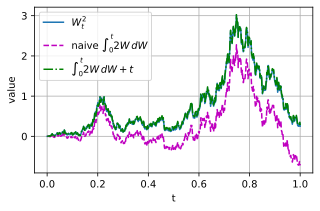

In [5]:
ito = np.concatenate([[0.0], np.cumsum(2 * W_lr[:-1] * dW_lr)])  # int 2W dW
gap = W_lr**2 - ito
print(f'final gap W_1^2 - int 2W dW = {gap[-1]:.4f}   (Ito correction: t = 1)')
print(f'max |gap_t - t| along the path = {np.abs(gap - t_lr).max():.4f}')
d2l.plot(t_lr, [W_lr**2, ito, ito + t_lr], 't', 'value',
         legend=['$W_t^2$', 'naive $\\int_0^t 2W\\,dW$',
                 '$\\int_0^t 2W\\,dW + t$'], figsize=(5, 3))

The curve labeled naive is the Itô integral $\int_0^t 2W\,dW$, which the
ordinary chain rule would take for $W_t^2$. It sags below $W_t^2$, and adding
$t$ puts it back on top. Along the whole path the gap usually stays within
about $0.1$ of $t$, since by the proof of the equation its standard
deviation at time $t$ is $\sqrt{2t\,\Delta t} \le 0.045$ on this grid. At
$t = 1$ the gap is the sum of squared increments that the earlier cell
printed.

**Example 2: geometric Brownian motion.** The SDE
$dX = \mu X\,dt + \nu X\,dW$ with $X_0 > 0$ models a quantity that grows at
mean rate $\mu$ with noise proportional to its size, such as a stock price
[@Black.Scholes.1973]. Its noise is multiplicative. Apply the lemma to
$\phi(x) = \log x$, with $\phi' = 1/x$, $\phi'' = -1/x^2$, and
$g^2 = \nu^2 x^2$. The logarithm is smooth only for $x > 0$, so assume for
the moment that $X$ stays positive:

$$
d\log X = \left(\mu - \tfrac12\nu^2\right) dt + \nu\, dW,
\qquad\textrm{so}\qquad
X_t = X_0 \exp\!\left(\left(\mu - \tfrac12\nu^2\right) t + \nu W_t\right).
$$

The formula we obtain is positive, and the lemma applied to it as a function
of $W_t$ and $t$ confirms that it solves the equation, which removes the
assumption. The $-\tfrac12\nu^2$ is the correction with $\phi'' < 0$: a concave function
loses from symmetric noise. Noise therefore lowers the typical growth rate
$\mu - \tfrac12\nu^2$ below the mean growth rate $\mu$, and
Exercise 3 shows how
far the mean and the median of $X_t$ drift apart. We will measure simulation
errors against this exact solution.

In several dimensions the pattern is the same, and we take the result as
given [@Oksendal.2003]. For
$d\mathbf{X} = \mathbf{f}\,dt + \mathbf{G}\,d\mathbf{W}$
with $\mathbf{X} \in \mathbb{R}^d$, a matrix $\mathbf{G}$, and a Brownian
motion $\mathbf{W}$ whose coordinates are independent scalar Brownian
motions, the multiplication table reads $dW_i\, dW_j = \delta_{ij}\,dt$,
and a twice continuously differentiable $\phi$ satisfies

$$
d\phi(\mathbf{X}) \;=\; \nabla\phi \cdot d\mathbf{X}
\;+\; \tfrac12 \sum_{i,j} \left(\mathbf{G} \mathbf{G}^\top\right)_{ij}
\frac{\partial^2\phi}{\partial x_i\, \partial x_j} \; dt .
$$

The correction weights each second derivative by the covariance rate
$\mathbf{G}\mathbf{G}^\top$ of the noise. The diffusion-model SDEs of this
chapter treat every coordinate alike, $\mathbf{G} = g(t)\,\mathbf{I}$, and for
them it reduces to
$\tfrac12 g(t)^2 \sum_i \partial^2\phi/\partial x_i^2\; dt$, a multiple of the
Laplacian of $\phi$. The next section needs the lemma in this form.

## The Ornstein--Uhlenbeck Process

The running example now gets its name and its solution. The
Ornstein--Uhlenbeck (OU) process [@Uhlenbeck.Ornstein.1930] is

$$
dX = -\theta X \, dt + g\,dW, \qquad \theta > 0,
$$

the decay ODE $\dot{x} = -\theta x$ of that section
with noise of constant amplitude $g$ added. Its authors wrote it for the
velocity of a particle that is kicked by molecules and slowed by friction.
The drift
pulls excursions back toward zero at rate $\theta$, and the noise keeps
producing new ones (the figure). The recurrence
of the opening is this process with $\theta = 1$ and $g = \sqrt{2}$, advanced
on a grid with step $h = 0.01$ by freezing the drift over each step: one step
multiplies by $1 - \theta h = 0.99$ and adds noise of standard deviation
$g\sqrt{h} = \sqrt{0.02}$.

![Mean reversion. The drift $-\theta x$ (arrows) pulls every path toward $0$ at rate $\theta=1$ while noise of amplitude $g=\sqrt2$ keeps it moving; paths from three starts forget them within a few multiples of $1/\theta$ and then fluctuate inside the band of two standard deviations of the limiting law, $\pm2\sqrt{g^2/2\theta}=\pm2$ (labeled stationary). Right: its density.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/mdl-dyn-ou-mean-reversion.svg)

### The Transition Kernel

The OU process is one of the few SDEs whose law is known in closed form at
every time, and this is why diffusion models are built on it. The law of
$X_t$ given the start $X_0 = x_0$, read as a function of the start, is called
the *transition kernel* (no relation to the kernels of a convolution). For
the OU process it is Gaussian. Of all the results of this section, this is
the one the rest of the book uses most.

**Proposition (OU transition kernel).** *For the OU process
the equation,*

$$
X_t \mid X_0 = x_0 \;\sim\; \mathcal{N}\!\left(
x_0\, e^{-\theta t},\;
\frac{g^2}{2\theta}\left(1 - e^{-2\theta t}\right)
\right).
$$

**Proof.** The integrating factor $e^{\theta t}$ solved the decay equation
with an input in that section (the variation of
constants formula the equation), and it works
when the input is noise. Apply Itô's lemma the equation to
$\phi(x, t) = e^{\theta t} x$, for which
$\phi_t = \theta e^{\theta t} x$, $\phi_x = e^{\theta t}$, and
$\phi_{xx} = 0$, so there is no correction:

$$
d\!\left(e^{\theta t} X_t\right)
= \left(\theta e^{\theta t} X_t - \theta e^{\theta t} X_t\right) dt
+ e^{\theta t} g\,dW_t
= g\, e^{\theta t}\,dW_t.
$$

The drift cancels, and integrating from $0$ to $t$ and multiplying by
$e^{-\theta t}$ gives

$$
X_t = X_0\, e^{-\theta t} + g \int_0^t e^{-\theta (t - s)}\, dW_s .
$$

The remaining integral has a deterministic integrand, so it is a limit of
weighted sums of independent Gaussian increments and is Gaussian with mean
zero (we grant that mean-square limits of Gaussians are Gaussian). The Itô
isometry the equation gives its variance:

$$
\textrm{Var}(X_t \mid X_0)
= g^2 \int_0^t e^{-2\theta (t - s)}\, ds
= \frac{g^2}{2\theta}\left(1 - e^{-2\theta t}\right).
\qquad \blacksquare
$$

The solution the equation reads as a fading memory. The
start decays at rate $\theta$, and a noise kick from time $s$ survives with
weight $e^{-\theta(t-s)}$: recent noise counts, old noise is forgotten. In the
recurrence a kick from $k$ steps ago survives with weight
$0.99^k \approx e^{-0.01k}$. Every later section,
and that section in the main text, writes the
kernel with two coefficients, the mean factor and the standard deviation,

$$
\alpha_t = e^{-\theta t}, \qquad
\sigma_t^2 = \frac{g^2}{2\theta}\left(1 - e^{-2\theta t}\right),
\qquad\textrm{so that}\qquad
X_t \mid X_0 = x_0 \sim \mathcal{N}\!\left(\alpha_t x_0,\, \sigma_t^2\right).
$$

The data enter only through the mean $\alpha_t x_0$, and the noise only
through the variance $\sigma_t^2$. For the running example ($\theta = 1$,
$g = \sqrt{2}$, $\sigma_t^2 = 1 - e^{-2t}$) started at $x_0 = 2$, the kernel is
$\mathcal{N}(1.213,\, 0.795^2)$ at $t = 0.5$, $\mathcal{N}(0.736,\, 0.930^2)$
at $t = 1$, and $\mathcal{N}(0.037,\, 1.000^2)$ at $t = 4$. Because the kernel is
Gaussian at every time and for every start, everything about the noised
state given its start is known in closed form, including the gradient of its
log-density, $-(x-\alpha_t x_0)/\sigma_t^2$. Generation will turn out to
depend on this gradient.

The recurrence is only a discretization of the process, so its cloud should
follow the kernel closely but need not follow it exactly. We run it as a
plain loop on $10{,}000$ copies of $x_0 = 2$, save the cloud at five times,
and print its mean and standard deviation next to $2\alpha_t$ and $\sigma_t$,
together with the fraction of the cloud inside $2\alpha_t \pm 2\sigma_t$.

In [6]:
theta_ou, g_ou, h_ou = 1.0, np.sqrt(2.0), 0.01
X_ou = np.full(10000, 2.0)                    # 10,000 copies of x_0 = 2
snap_steps = {round(t / h_ou): t for t in (0.5, 1.0, 1.5, 2.0, 4.0)}
X_ou_snap = {}
for k in range(1, 401):
    xi = rng.standard_normal(X_ou.size)
    X_ou = (1 - theta_ou * h_ou) * X_ou + g_ou * np.sqrt(h_ou) * xi
    if k in snap_steps:
        X_ou_snap[snap_steps[k]] = X_ou.copy()
print(f'{"t":>4} {"mean":>6} {"2alpha_t":>8} {"std":>6} {"sigma_t":>7}'
      f' {"inside":>7}')
for t, X in X_ou_snap.items():
    alpha_t = np.exp(-theta_ou * t)
    sigma_t = np.sqrt(g_ou**2 / (2 * theta_ou) * (1 - alpha_t**2))
    inside = np.mean(np.abs(X - 2 * alpha_t) < 2 * sigma_t)
    print(f'{t:4.1f} {X.mean():6.3f} {2 * alpha_t:8.3f} {X.std():6.3f} '
          f'{sigma_t:7.3f} {inside:7.3f}')

   t   mean 2alpha_t    std sigma_t  inside
 0.5  1.209    1.213  0.803   0.795   0.951
 1.0  0.733    0.736  0.943   0.930   0.955
 1.5  0.433    0.446  0.968   0.975   0.957
 2.0  0.259    0.271  0.992   0.991   0.953
 4.0  0.042    0.037  1.012   1.000   0.952


Means and standard deviations agree with the kernel within two or three
standard errors (about $0.01$ for a mean and $0.007$ for a standard deviation
from $10{,}000$ samples). About $95\%$ of the cloud lies inside the band at
every time, as for any Gaussian. The cloud that began as the single point
$2$ widens quickly and then stops widening. At this sample size the
discretization cannot be seen.

### The Stationary Distribution

A forward process must forget its start, and the kernel
the equation shows that the OU process does. As
$t \to \infty$ the mean $x_0 e^{-\theta t}$ decays to zero and the variance
approaches $g^2/(2\theta)$, so

$$
X_t \mid X_0 = x_0 \;\longrightarrow\; \mathcal{N}\!\left(0, \, \frac{g^2}{2\theta}\right)
\quad \textrm{in distribution, for every } x_0 .
$$

This is the endpoint, the same for all data, that
that section asked for. The limit is more than an
endpoint. A process started in it stays in it, and a law with this property
is called *stationary*. To see it, let $X_0 \sim \mathcal{N}(0, g^2/2\theta)$
be independent of $W$. By the equation, $X_t$ is then the
sum of $X_0 e^{-\theta t}$ and an independent Gaussian of variance
$\sigma_t^2$, hence Gaussian with mean zero and variance

$$
e^{-2\theta t}\,\frac{g^2}{2\theta}
+ \frac{g^2}{2\theta}\left(1 - e^{-2\theta t}\right)
= \frac{g^2}{2\theta}.
$$

The decay of the start removes as much variance as the noise adds. How long
does the forgetting take? Its time scale is $1/\theta$, the *relaxation
time*, and after a few multiples of it $e^{-\theta t}$ is negligible. For the
running example $g^2/2\theta = 1$ and $1/\theta = 1$, so the stationary law
is $\mathcal{N}(0, 1)$, and by $t = 4$ the mean had fallen from $2$ to
$0.037$.

The recurrence has a stationary law of its own, and it is slightly different.
One step maps a variance $v$ to $(1 - \theta h)^2 v + g^2 h$. From $v = 1$ a
step of the running example gives $0.9801 + 0.02 = 1.0001$, slightly more than
$1$, and the fixed point of the map is

$$
v_\infty = \frac{g^2 h}{1 - (1 - \theta h)^2} = \frac{0.02}{0.0199} = 1.005
\qquad (h = 0.01).
$$

The recurrence therefore settles half a percent above the exact variance $1$.
No cloud of $10{,}000$ points can show half a percent, but the pencil can.
This is the first sign of a discretization error, and
that section shows that it shrinks in proportion to $h$.

### The Variance-Preserving Normalization

The stationary variance $g^2/2\theta$ is a free parameter, and diffusion
models fix it to $1$ by choosing

$$
g^2 = 2\theta
\qquad \Longrightarrow \qquad
X_t \mid X_0 = x_0 \;\longrightarrow\; \mathcal{N}(0, 1).
$$

The running example makes this choice. With it
$\sigma_t^2 = 1 - \alpha_t^2$, so one coefficient describes the kernel.

So far the start was a single number $x_0$. Let it now be a draw $X_0$ from
the data. In distribution, the solution the equation then
reads $X_t = \alpha_t X_0 + \sqrt{1 - \alpha_t^2}\,\epsilon$ with a
standard Gaussian $\epsilon$ independent of $X_0$. The law of this $X_t$,
which is the kernel averaged over the data, is called the *marginal* at
time $t$. Most papers write it with another letter. They follow the
denoising diffusion probabilistic model (DDPM) of @ho2020denoising,
the discrete-time diffusion model of that section,
which writes $\bar{\alpha}_t$ for our $\alpha_t^2 = e^{-2\theta t}$. The
main text does the same, and so do we:

$$
X_t \;=\; \sqrt{\bar{\alpha}_t}\; X_0 \;+\; \sqrt{1 - \bar{\alpha}_t}\;
\epsilon, \qquad \epsilon \sim \mathcal{N}(0, 1)
\textrm{ independent of } X_0 .
$$

The marginal is a weighted mix of data and fresh noise, with weights whose
squares add to one. Suppose the data have zero mean and unit variance. Taking
variances of the two independent terms gives

$$
\textrm{Var}(X_t)
= \bar{\alpha}_t \textrm{Var}(X_0) + (1 - \bar{\alpha}_t)
= \bar{\alpha}_t + (1 - \bar{\alpha}_t) = 1
\qquad \textrm{for all } t.
$$

This is what **variance-preserving** (VP) means. For unit-variance data the
marginal variance equals $1$ at every time, not only in the limit. The process
moves variance from the data to the noise, a fraction $\bar{\alpha}_t$ still
carried by the data and $1 - \bar{\alpha}_t$ already replaced by noise,
without changing the total. The name is accurate for unit-variance data only.
For data of variance $s^2$ the marginal variance drifts from $s^2$ to $1$
(Exercise 5), so the scale of
the data matters. Images scaled to $[-1, 1]$, as in
that section, have variance below one, while latent
diffusion models rescale their latents to about unit variance
[@Rombach.Blattmann.Lorenz.ea.2022].

The variance is preserved; the shape of the distribution is not. Take data
that are $\pm 1$ with probability $\tfrac12$ each, the outcome of a coin
flip. Their fourth moment is $1$, against $3$ for a standard Gaussian, and
along the process it climbs as
$\mathbb{E}[X_t^4] = 3 - 2\bar{\alpha}_t^2$, which is $2.264$ at $t = 0.25$
and $2.963$ at $t = 1$ for the running example (same exercise). The coin
turns into a bell curve, and its variance never moves.

Diffusion models usually let the rate vary with time. The **VP-SDE** of
score-based diffusion [@song2021score],

$$
dX = -\tfrac12 \beta(t)\, X \, dt + \sqrt{\beta(t)}\; dW,
$$

is an OU process with time-dependent rate $\theta(t) = \beta(t)/2$ and noise
amplitude $g(t)^2 = \beta(t)$; the running example is the constant schedule
$\beta = 2$. It keeps $g^2 = 2\theta$ at every instant, so
the variance stays at $1$ along the whole schedule, and its marginal is
the equation with $\bar{\alpha}_t = e^{-\int_0^t \beta(s)\,ds}$
(Exercise 7 proves that its
transitions are exact Gaussians). This is the variance-preserving path of
that section, the forward process that a diffusion
model learns to reverse.

## Simulation

### The Euler--Maruyama Scheme

Most SDEs have no closed-form solution, so we need to simulate them. Our
recurrence already shows how. To simulate the equation on a
grid $t_n = n\,\Delta t$ we freeze the coefficients over each step, as forward Euler does for ODEs
(that section), and add a Gaussian kick whose size the
increment form the equation dictates. The
**Euler--Maruyama** update [@Maruyama.1955] is

$$
\hat{X}_{n+1} = \hat{X}_n + f(\hat{X}_n, t_n)\,\Delta t
+ g(\hat{X}_n, t_n)\,\sqrt{\Delta t}\;\xi_n,
\qquad \xi_n \sim \mathcal{N}(0, 1) \textrm{ i.i.d.},
$$

where $\hat{X}_n$ approximates $X_{t_n}$ and $\hat X_0 = X_0$. The kick
scales as $\sqrt{\Delta t}$, since any other exponent makes the noise vanish
or explode in the limit (that section), and with $g = 0$
the scheme is forward Euler.

For the OU process the step reads

$$
\hat{X}_{n+1} = (1 - \theta\,\Delta t)\,\hat{X}_n + g\sqrt{\Delta t}\;\xi_n
= 0.99\,\hat{X}_n + 0.1414\,\xi_n ,
$$

where the second form is the running example at $\Delta t = h = 0.01$, the
recurrence we have been running all along.

For this process we could have done better. With $g^2 = 2\theta$ the kernel
the equation over one interval is
$\mathcal{N}(e^{-\theta\Delta t}x, 1 - e^{-2\theta\Delta t})$, and sampling
from it is the forward step of DDPM
(that section),
$x_k = \sqrt{1 - \beta_k}\, x_{k-1} + \sqrt{\beta_k}\,\epsilon_k$ with
$\beta_k = 1 - e^{-2\theta\Delta t}$. DDPM's step is therefore exact at every
step size, and Euler--Maruyama is its first-order approximation. At
$\theta = 1$ and $\Delta t = 0.01$ the exact step multiplies by
$e^{-0.01} = 0.99005$ and adds noise of variance
$\beta_k = 1 - e^{-0.02} = 0.0198$, against $0.99$ and $0.02$. The two betas
should not be confused. The $\beta_k$ of the step is the fraction of the
variance that one step replaces by noise. It is about $\beta(t)\,\Delta t$
for the rate $\beta(t)$ of the equation, here $0.0198$ against
$2 \cdot 0.01$. Exact steps need a linear equation
(Exercise 7). A general drift has
no transition law in closed form, and the approximate scheme is all we have.

The helper below implements the equation for a whole batch of
paths. It takes the increments $\Delta W$ as an argument, so that two
simulations can be driven by the same noise. We need that at once: with the
noise switched on, "error" itself needs a definition, and there are two.

In [7]:
def euler_maruyama(f, g, x0, t, dW):
    """Simulate dX = f dt + g dW on the grid t for a batch of paths."""
    X = np.empty((len(x0), len(t)))
    X[:, 0] = x0
    for k in range(len(t) - 1):
        h = t[k + 1] - t[k]
        X[:, k + 1] = (X[:, k] + f(X[:, k], t[k]) * h
                       + g(X[:, k], t[k]) * dW[:, k])
    return X

### Strong and Weak Convergence

A simulated path is random, and so is the true one. The two definitions of
error differ in what they compare: paths or laws, the two kinds of statement
that the band experiment told apart.

Let $N = T/\Delta t$ be the number of steps, so that $\hat{X}_N$ approximates
$X_T$. Drive the scheme and the exact solution with the same Brownian
increments. The **strong error** $\mathbb{E}\,|\hat{X}_N - X_T|$ measures
pathwise tracking: does the simulated trajectory follow the true trajectory
driven by that noise? The **weak error**
$|\mathbb{E}\,\varphi(\hat{X}_N) - \mathbb{E}\,\varphi(X_T)|$, for smooth test
functions $\varphi$, measures only whether the law at time $T$ comes out
right. A generative model needs weak accuracy, since it only uses the samples
at the final time. Strong accuracy matters when paths are coupled across
resolutions, as in multilevel Monte Carlo, which makes most of its estimate
on cheap coarse paths and corrects it with a few expensive fine ones
(Exercise 8).
the figure shows the two notions side by side.

![Strong versus weak convergence of Euler--Maruyama on the running example from $X_0=2$ on $[0,1]$. Left: one coarse path ($16$ steps, orange) against a fine reference ($4096$ steps, blue) driven by the same Brownian increments; the strip below magnifies their gap at the coarse grid times, which is what the strong error measures. Right: the terminal histograms of $20{,}000$ paths at the two step sizes nearly match each other and the exact law (black), although at $16$ steps the variance is about $4\%$ too large.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/mdl-dyn-strong-weak.svg)

A scheme has strong order $p$ if its strong error is at most
$C\,\Delta t^{p}$, and weak order $p$ likewise. The orders of
Euler--Maruyama are classical.

**Theorem (orders of Euler--Maruyama; stated without proof).** *Let $f$, $g$,
and $\varphi$ be smooth, with the growth conditions and the moments of $X_0$
that @Kloeden.Platen.1992 make precise.*

1. *Euler--Maruyama has strong order $\tfrac12$:
   $\mathbb{E}\,|\hat{X}_N - X_T| \le C\,\Delta t^{1/2}$.*
2. *If the noise is additive, $g = g(t)$, the strong order is $1$:
   $\mathbb{E}\,|\hat{X}_N - X_T| \le C\,\Delta t$.*
3. *The weak order is $1$, for additive and multiplicative noise alike:
   $|\mathbb{E}\,\varphi(\hat{X}_N) - \mathbb{E}\,\varphi(X_T)| \le C\,\Delta t$.*

A count of single-step errors explains the exponents. It is not a proof: it
adds the errors of the steps as if each stayed where it was made, and the
proofs must also control how the later dynamics carry an early error forward.

Euler--Maruyama freezes $g$ over the step, but $g$ moves with the path. At a
time $s$ inside the step the path has moved by about $g\,(W_s - W_{t_n})$, so
the noise coefficient there is about
$g + g\,\partial_x g\,(W_s - W_{t_n})$. The largest term that the scheme
leaves out is the integral of the second part against $dW$, which is
the equation for the Brownian motion $W_s - W_{t_n}$ that starts
afresh at $t_n$:

$$
g\,\partial_x g \int_{t_n}^{t_{n+1}} \left(W_s - W_{t_n}\right) dW_s
= \tfrac12\, g\,\partial_x g\left((\Delta W)^2 - \Delta t\right).
$$

Milstein's scheme puts this term back [@Milstein.1975]. Its random
factor is the rule for squares seen a step at a time: $(\Delta W)^2 = \Delta t$
is true in sums, and off by something of mean zero and size $\Delta t$ in
every step. The $N = T/\Delta t$ steps contribute uncorrelated terms of this
kind, which add like a random walk to
$\sqrt{N}\,\Delta t = \sqrt{T\,\Delta t}$. That is order $\tfrac12$.

For additive noise $\partial_x g = 0$ removes this term. The next omitted
stochastic terms have size $\Delta t^{3/2}$ per step and add to
$\sqrt{N}\,\Delta t^{3/2} = O(\Delta t)$, as do the deterministic remainders,
$N\,\Delta t^2 = O(\Delta t)$, and the order is $1$. For the weak error only
means matter. Every omitted stochastic term has mean zero, the bias of one step is
of order $\Delta t^2$, and $N$ steps give $O(\Delta t)$, whatever the noise.

We measure both strong orders on the same noise. Geometric Brownian motion
($\mu = \nu = 1$, $X_0 = 1.5$) is compared with its exact solution
the equation, and the running example from $X_0 = 2$ with a
reference on a $4096$-step grid, since the noise integral in its exact
solution the equation could itself be evaluated only on a
grid. Coarse increments are sums of consecutive fine ones, so every
resolution sees the same Brownian path.

strong-order slopes:  OU (additive) 1.03,  GBM (multiplicative) 0.48


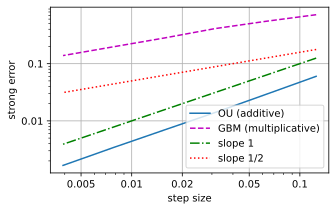

In [8]:
T, n_ref, n_em = 1.0, 2**12, 2000
mu_g, nu_g = 1.0, 1.0                        # GBM: multiplicative noise
ou_f, ou_g = lambda x, s: -theta_ou * x, lambda x, s: g_ou
gbm_f, gbm_g = lambda x, s: mu_g * x, lambda x, s: nu_g * x
x0_ou, x0_gbm = np.full(n_em, 2.0), np.full(n_em, 1.5)
dW_f = np.sqrt(T / n_ref) * rng.standard_normal((n_em, n_ref))
t_f = np.linspace(0, T, n_ref + 1)
ou_ref = euler_maruyama(ou_f, ou_g, x0_ou, t_f, dW_f)[:, -1]
gbm_exact = 1.5 * np.exp((mu_g - nu_g**2 / 2) * T + nu_g * dW_f.sum(axis=1))
dts, errs_ou, errs_gbm = [], [], []
for n in [2**k for k in range(3, 9)]:        # 8 to 256 steps
    dW = dW_f.reshape(n_em, n, n_ref // n).sum(axis=2)
    t = np.linspace(0, T, n + 1)
    ou = euler_maruyama(ou_f, ou_g, x0_ou, t, dW)[:, -1]
    gbm = euler_maruyama(gbm_f, gbm_g, x0_gbm, t, dW)[:, -1]
    dts.append(T / n)
    errs_ou.append(np.abs(ou - ou_ref).mean())
    errs_gbm.append(np.abs(gbm - gbm_exact).mean())
print('strong-order slopes:  OU (additive) '
      f'{np.polyfit(np.log(dts), np.log(errs_ou), 1)[0]:.2f},'
      '  GBM (multiplicative) '
      f'{np.polyfit(np.log(dts), np.log(errs_gbm), 1)[0]:.2f}')
d2l.plot(dts, [errs_ou, errs_gbm, np.array(dts), 0.5 * np.sqrt(dts)],
         'step size', 'strong error', xscale='log', yscale='log',
         legend=['OU (additive)', 'GBM (multiplicative)',
                 'slope 1', 'slope 1/2'], figsize=(5, 3))

The measured slopes are close to $1$ for the additive-noise OU process and
close to $\tfrac12$ for the multiplicative-noise geometric Brownian motion,
the two strong orders of the theorem. The two curves have different heights
because the processes have different scales. What can be compared is how
they fall: each halving of the step halves the OU error and divides the
error of geometric Brownian motion by about $\sqrt{2}$.

For the weak order no sampling is needed. Euler--Maruyama applied to the OU
process is a linear Gaussian recursion: if $\hat{X}_n$ is Gaussian, so is
$\hat{X}_{n+1}$. So the simulated marginal is Gaussian at every step, with mean
and variance

$$
m_{n+1} = (1 - \theta\,\Delta t)\,m_n,
\qquad
v_{n+1} = (1 - \theta\,\Delta t)^2\, v_n + g^2\,\Delta t .
$$

The mean is multiplied by $1 - \theta\Delta t$ per step where the exact
solution multiplies by $e^{-\theta\Delta t}$ ($0.900$ against $0.905$ at
$\Delta t = 0.1$). The variance recursion sums a geometric series,
$v_n = g^2\Delta t\,(1 - a^{2n})/(1 - a^2)$ with $a = 1 - \theta\Delta t$
and $v_0 = 0$, whose limit is the fixed point $v_\infty$ found earlier.
Evaluating these closed forms at $T = 1$ from $X_0 = 2$ for six step counts
gives the errors of the simulated law with no sampling error to blur their
slopes.

In [9]:
mean_T, var_T = 2 * np.exp(-1), 1 - np.exp(-2)  # exact OU kernel at T = 1
print(f'{"n":>4} {"EM mean":>8} {"EM var":>7}'
      f'   exact {mean_T:.4f}, {var_T:.4f}')
dts, errs = [], []
for n in [10, 20, 40, 80, 160, 320]:
    h = 1 / n
    a_h = 1 - theta_ou * h                   # one-step mean multiplier
    m = 2 * a_h**n                           # EM mean after n steps
    v = g_ou**2 * h * (1 - a_h**(2 * n)) / (1 - a_h**2)   # geometric series
    print(f'{n:4d} {m:8.4f} {v:7.4f}')
    dts.append(h)
    errs.append([abs(m - mean_T), abs(v - var_T)])
s_m, s_v = np.polyfit(np.log(dts), np.log(np.array(errs)), 1)[0]
print(f'weak-order slopes:  mean {s_m:.2f},  variance {s_v:.2f}')

   n  EM mean  EM var   exact 0.7358, 0.8647
  10   0.6974  0.9247
  20   0.7170  0.8938
  40   0.7265  0.8791
  80   0.7311  0.8718
 160   0.7335  0.8682
 320   0.7346  0.8664
weak-order slopes:  mean 1.01,  variance 1.01


At $10$ steps the simulated law has mean $0.697$ and variance $0.925$,
against the exact $0.736$ and $0.865$ (the kernel
$\mathcal{N}(0.736,\, 0.930^2)$ from before), and at $320$ steps it has
$0.735$ and $0.866$. Both fitted slopes are $1.01$: halving the step halves
the error of the simulated law, which is weak order $1$.

The same computation for geometric Brownian motion also gives weak order $1$,
so multiplicative noise costs half an order in the paths and nothing in the
law. A scheme that looks more accurate can even converge to the wrong
equation. Heun's method, which averages the noise coefficient over the step,
converges to the Stratonovich solution instead of the Itô one
(Exercise 6).

Simulation produces samples of the forward process, and the kernel gives its
law from a single start. Generation asks for more. Data are not a single
point: the marginal $p_t$ of the noised data is the kernel averaged over all
starts, and for real data, which we know only through samples, it has no
closed form. Yet running the process backward will require the gradient of
$\log p_t$, the quantity that we could write down for one start, and so far
we do not even have an equation that $p_t$ obeys.

## Summary

A forward process must forget its start, which no deterministic flow can do,
so it is driven by noise. Noise that survives the limit of small steps has
size $\sqrt{\Delta t}$, and the squares of its increments add up to the
elapsed time, $(dW)^2 = dt$. An integral against $dW$ therefore depends on
where its integrand is evaluated, and Itô's left endpoint gives it mean zero
and the isometry $\mathbb{E}[(\int H\,dW)^2] = \int \mathbb{E}[H^2]\,ds$.
For the same reason the chain rule gains the correction
$\tfrac12 g^2 \phi_{xx}\,dt$. With these tools the Ornstein--Uhlenbeck
process $dX = -\theta X\,dt + g\,dW$ is solved: given its start $x_0$ it is
Gaussian at every time, with mean $x_0 e^{-\theta t}$ and variance
$\tfrac{g^2}{2\theta}(1 - e^{-2\theta t})$, and with $g^2 = 2\theta$ it is
the variance-preserving forward process of diffusion models. Equations
without a closed form are simulated by Euler--Maruyama, Euler's step plus a
$\sqrt{\Delta t}$ kick, which follows paths at order $1$ for additive noise
and $\tfrac12$ for multiplicative noise and reproduces laws at order $1$ for
both.

## Exercises

1. **Infinite total variation.** The total variation of a path $x$ along a
   partition $0 = t_0 < t_1 < \cdots < t_n = t$ is
   $V_n = \sum_i |x(t_{i+1}) - x(t_i)|$. Pathwise integrals
   $\int H\,dx$, defined as limits of sums $\sum_i H(s_i)\,\Delta x_i$ with
   arbitrary evaluation points $s_i \in [t_i, t_{i+1}]$, exist for every
   continuous $H$ when $V_n$ stays bounded as the mesh shrinks.
    1. Let $x = W$ and use the uniform partition with $\Delta t_i = t/n$.
       Compute $\mathbb{E}[V_n]$ and $\textrm{Var}(V_n)$, using
       $\mathbb{E}|\xi| = \sqrt{2/\pi}$ for $\xi \sim \mathcal{N}(0, 1)$, and
       conclude that $V_n \to \infty$ in probability as $n \to \infty$.
    1. Let $x$ be continuous with $V_n \le V$ for every partition. Show that
       $\max_i |\Delta x_i| \to 0$ as the mesh shrinks, and deduce
       $\sum_i (\Delta x_i)^2 \le \max_i |\Delta x_i| \cdot V \to 0$: such a
       path has quadratic variation zero. Why does the equation
       then give a second proof that Brownian paths have unbounded total
       variation?
    1. Let $x$ be continuous with bounded total variation. Show that the
       left-endpoint sums $\sum_i x(t_i)\,\Delta x_i$ and the right-endpoint
       sums $\sum_i x(t_{i+1})\,\Delta x_i$ both converge to
       $\tfrac12\left(x(t)^2 - x(0)^2\right)$. Compare with the two limits
       for $x = W$ in that section. Which step of your
       argument fails for a Brownian path?

1. [code] **Brownian scaling and exit times.**
    1. For $c > 0$ let $\tilde{W}_t = W_{ct}/\sqrt{c}$. Check properties 1–4
       of that section and conclude that $\tilde{W}$ is a
       Brownian motion. Which property of the $\pm\sqrt{\Delta t}$ walk does
       this make exact?
    1. Let $\tau_a$ be the first time $|W_t|$ reaches a level $a > 0$. Use (a)
       to show that $\tau_a$ has the same distribution as $a^2 \tau_1$, so
       that $\mathbb{E}[\tau_a] = a^2\, \mathbb{E}[\tau_1]$.
    1. Granting $\mathbb{E}[\tau_1] = 1$ (it follows from
       $\mathbb{E}[W_{\tau}^2] = \mathbb{E}[\tau]$, a consequence of
       the equation and the zero mean of the Itô integral up to a
       stopping time), simulate $4{,}000$ walks with Gaussian steps of
       variance $\Delta t = 10^{-3}$ and estimate $\mathbb{E}[\tau_a]$ for
       $a = 0.5, 1, 2$, with Monte Carlo standard errors. The estimates tend
       to run slightly above $a^2$, most clearly for small $a$. Explain the
       sign of the bias from the way a discrete walk crosses a level, and say
       how it scales with $a$ and $\Delta t$.
    1. In the experiment of the text a little over half of the paths stay
       inside $\pm 2\sqrt{t}$ at all $500$ grid times. Use (a) to show that
       this fraction depends only on the number $n$ of grid times and not on
       the length of the interval. Measure it for $n = 50$, $500$, and
       $5000$. By what factor does it fall each time $n$ grows tenfold, and
       what does that say about the limit $n \to \infty$?

1. **Geometric Brownian motion and the $-\nu^2/2$ correction.** Consider
   $dX = \mu X\,dt + \nu X\,dW$ with $X_0 > 0$ and its solution, given
   by the equation.
    1. Using $\mathbb{E}\big[e^{\lambda Z}\big] = e^{\lambda^2 v/2}$ for
       $Z \sim \mathcal{N}(0, v)$, show that
       $\mathbb{E}[X_t] = X_0 e^{\mu t}$ and
       $\mathbb{E}[X_t^2] = X_0^2 e^{(2\mu + \nu^2) t}$. Find the median
       of $X_t$.
    1. Take $\mu = 0.1$ and $\nu = 0.6$. What happens to the mean, to the
       median, and to a typical path as $t \to \infty$? How can these
       statements hold at the same time?
    1. For which $\nu$, at a fixed $\mu > 0$, does the median stop growing?
       Check the condition for the parameters of (b) on $100$ paths
       simulated with `euler_maruyama` to $t = 20$ at $\Delta t = 10^{-2}$:
       what fraction of the paths ends below $X_0$, and what fraction does
       the exact solution the equation predict?

   *Adapted from Simo Särkkä and Arno Solin,
   [Applied Stochastic Differential Equations](https://users.aalto.fi/~asolin/sde-book/sde-book.pdf),
   Exercise 4.3.*

1. [code] **Strong order and Milstein's correction.** As
   that section explains, Euler--Maruyama omits the
   Milstein term
   $\tfrac12 g\,\partial_x g\left((\Delta W)^2 - \Delta t\right)$, and its
   strong order is $\tfrac12$ unless that term vanishes.
    1. By the equation, $Y = \log X$ satisfies an SDE with
       additive noise. Apply `euler_maruyama` to that SDE with the
       increments `dW_f` and the step sizes of the strong-order
       experiment, exponentiate the endpoints, and measure the strong error against
       `gbm_exact`. Explain the result.
    1. Use Itô's lemma to show that for $dX = f(X)\,dt + g(X)\,dW$ with
       $g > 0$, the variable $Y = \psi(X)$ with $\psi' = 1/g$ has unit
       additive noise, and find its drift.
    1. Milstein's scheme [@Milstein.1975] adds that term to the
       Euler--Maruyama step,

       $$\hat X_{n+1} = \hat X_n + f\,\Delta t + g\,\Delta W_n + \tfrac12\, g\,\partial_x g\left((\Delta W_n)^2 - \Delta t\right),$$

       with $f$, $g$, and $\partial_x g$ evaluated at $(\hat X_n, t_n)$.
       Implement it for the geometric Brownian motion of the strong-order
       experiment, and measure its strong-order slope on the same increments
       and step sizes. By what factor does it reduce the
       strong error at $\Delta t = 2^{-8}$?

1. **Variance preservation, exactly.** Let $X_t$ follow
   the equation with zero-mean data $X_0$.
    1. Assume unit-variance data and show that
       $\mathbb{E}[X_t^4] = 3 + \bar{\alpha}_t^2\left(\mathbb{E}[X_0^4] - 3\right)$.
       Specialize to Rademacher data $X_0 = \pm 1$ to obtain the prediction
       $3 - 2\bar{\alpha}_t^2$ of the text.
    1. The excess kurtosis $\mathbb{E}[X^4]/\textrm{Var}(X)^2 - 3$ is
       zero for every Gaussian. At what rate in $t$ does it decay for
       $X_t$? Compare this rate with the rate at which the conditional mean
       $\mathbb{E}[X_t \mid X_0]$ forgets the data.
    1. Suppose instead that the data have variance $s^2$. Find
       $\textrm{Var}(X_t)$. For $s = 2$ and $\theta = 1$, how long must
       the process run before $\textrm{Var}(X_T)$ is within $1\%$ of
       the variance of the reference $\mathcal{N}(0, 1)$?

1. [code] **Itô versus Stratonovich.** ● The left- and right-endpoint sums
   for $\int_0^t W\,dW$ add up to $W_t^2$ on every partition
   (that section), so their average equals
   $\tfrac12 W_t^2$. Sums of this kind define the Stratonovich integral
   [@Stratonovich.1966], which obeys the ordinary chain rule.
    1. Heun's method of that section carries over to
       SDEs if the noise term is treated like a second slope. The predictor
       is the Euler--Maruyama step
       $\tilde{X} = \hat X_n + f(\hat X_n)\,\Delta t + g(\hat X_n)\,\Delta W_n$,
       and the corrector averages both coefficients:

       $$\hat X_{n+1} = \hat X_n + \tfrac12\left[f(\hat X_n) + f(\tilde{X})\right]\Delta t + \tfrac12\left[g(\hat X_n) + g(\tilde{X})\right]\Delta W_n.$$

       Implement it for the geometric Brownian motion of the strong-order
       experiment, on its increments `dW_f` and step sizes. Compare its endpoints with the exact Itô solution
       the equation and with $X_0 \exp(\mu T + \nu W_T)$. To which
       of the two does the scheme converge?
    1. Expand the corrector's noise term to first order in
       $\tilde{X} - \hat X_n$, and use $(\Delta W_n)^2 \approx \Delta t$ to
       show that the scheme behaves like Euler--Maruyama for an Itô SDE with
       a modified drift. Find that drift and check that it explains the limit
       in (a).
    1. Why do the two conventions give the same solution for every SDE of
       the form the equation?

1. **Exact transitions of linear SDEs.** ● Consider the linear SDE
   $dX = -\theta(t) X\,dt + g(t)\,dW$ with continuous $\theta$ and
   $g$, and let $\Theta(t) = \int_0^t \theta(u)\,du$.
    1. Apply Itô's lemma to $\phi(x, t) = e^{\Theta(t)} x$ and show that,
       given $X_s$, the state $X_t$ at a later time $t$ is Gaussian with mean
       $e^{-(\Theta(t) - \Theta(s))} X_s$ and variance
       $\int_s^t e^{-2(\Theta(t) - \Theta(u))}\, g(u)^2\, du$.
    1. Specialize (a) to the VP-SDE the equation and show that
       a transition of any length maps a unit-variance state to a
       unit-variance state. Conversely, assume for the linear SDE of (a) that
       $\textrm{Var}(X_t) = 1$ for every $t \ge 0$ whenever
       $\textrm{Var}(X_0) = 1$, and show that
       $g(t)^2 = 2\,\theta(t)$ at every $t$.
    1. Consider the semilinear SDE
       $dX = \left(-\theta X + q(X)\right)dt + g\,dW$ with constants
       $\theta, g > 0$ and a smooth function $q$. The exponential
       Euler--Maruyama step holds $q$ at the value $q(\hat X_n)$ over a step
       of length $\Delta t$ and solves the remaining linear SDE exactly, by
       the method of (a). Write the step. Show that it agrees with the
       Euler--Maruyama step the equation to first order in
       $\Delta t$ and that it is exact when $q$ is constant. For
       $q \equiv 0$, Euler--Maruyama damps the mean only for
       $\Delta t < 2/\theta$ (that section). What
       limits the step size of the exponential step?
    1. Exact steps have zero weak error at every step size. Which property
       of the drift and the diffusion of the VP-SDE makes them available?
       The generative sampler of a diffusion model simulates,
       backward in time, an SDE whose drift is
       $-\tfrac12\beta(t)\,x - \beta(t)\,\nabla \log p_t(x)$: the VP drift
       plus a multiple of $\nabla \log p_t$, the *score* of the forward
       marginal, which is a nonlinear function of $x$ for non-Gaussian data.
       Why can its steps not be made exact? Exponential integrators for
       diffusion samplers [@Zhang.Chen.2023] apply the idea of (c) to
       the deterministic counterpart of this sampler, an ODE whose drift has
       the same two parts with half the score term
       (that section). Which part of
       such a drift does the step treat exactly, and which part does it
       approximate?

1. [extended] **Multilevel Monte Carlo.** ●● Estimating
   $\mathbb{E}[\varphi(X_T)]$ by averaging over Euler--Maruyama paths has two
   sources of error, the weak bias of the scheme and the sampling noise.
   Multilevel Monte Carlo [@Giles.2008] reduces the cost by coupling
   paths across step sizes, which is one of the uses of strong accuracy named
   in that section. Throughout, the mean-square strong
   error $\mathbb{E}\big[(\hat X_N - X_T)^2\big]^{1/2}$ has the same
   orders as the strong error of that section.
    1. Plain Monte Carlo averages $\varphi(\hat X_N)$ over $M$
       independent paths at a cost of $MT/\Delta t$ steps. Assume a weak
       bias $c_1\,\Delta t$ and a variance $v$ of $\varphi(\hat X_N)$.
       Show that a mean squared error below $\varepsilon^2$ costs order
       $\varepsilon^{-3}$ steps at the best choice of $M$ and $\Delta t$.
    1. Let $P_l$ be $\varphi$ of the Euler--Maruyama endpoint with step
       $h_l = T\,2^{-l}$, and write
       $\mathbb{E}[P_L] = \mathbb{E}[P_0] + \sum_{l=1}^{L}\mathbb{E}[P_l - P_{l-1}]$.
       Each term is estimated from $M_l$ independent pairs in which the coarse
       path uses the sums of consecutive pairs of fine increments, as in
       the strong-order experiment. For Lipschitz $\varphi$, bound
       $V_l = \textrm{Var}(P_l - P_{l-1})$ by the mean-square strong
       error. Take $\varphi(x) = x$, and predict how $V_l$ scales with $h_l$
       for the OU process and the geometric Brownian motion of that
       experiment, with its parameters. Measure $V_l$
       for $l = 1, \ldots, 8$ with `euler_maruyama`, and fit the slopes on
       the finer levels.
    1. Minimize the total cost $\sum_l M_l / h_l$ subject to
       $\sum_l V_l / M_l \le \varepsilon^2 / 2$ with a Lagrange multiplier.
       Choose the finest level $L$ so that the bias stays below
       $\varepsilon / \sqrt{2}$. Assuming $V_l \propto h_l^{r}$, show that
       the cost is of order $\varepsilon^{-2}$ for $r = 2$ and of order
       $\varepsilon^{-2} (\log \varepsilon)^2$ for $r = 1$.
    1. Implement both estimators for $\mathbb{E}[X_T] = X_0 e^{\mu T}$ of the
       geometric Brownian motion of the strong-order experiment, with $M_l$ from
       (c) and your measured $V_l$. For
       $\varepsilon \in \{0.2, 0.1, 0.05, 0.02\}$, record the total number of
       steps each estimator uses and check its error over a few repetitions.
       Plot $\varepsilon^2$ times the cost against $\varepsilon$. Repeat with
       the Milstein scheme of Exercise 4c
       in place of Euler--Maruyama. `euler_maruyama` stores every path in
       full, so simulate large $M_l$ in batches.
    1. Repeat the measurement of (b) for the discontinuous
       $\varphi(x) = \mathbf{1}(x > X_0)$. Why does $V_l$ decay more slowly,
       and what does the slower decay do to the cost?

[Discussions](https://d2l.discourse.group/t/36838)